# Hierarchical and DBSCAN Clustering on the Wine Dataset
**Student Name:** Sandesh Ghimire  

---

## Step 1: Data Preparation and Exploration

The Wine dataset contains thirteen chemical measurements from 178 wines grown by three cultivars. As in the earlier clustering lab, the cultivar labels are kept aside and used only to score the clusterings afterwards, never to fit them.

Both algorithms in this lab rely on distances, so the features must be on a comparable scale before anything else happens.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True

wine = load_wine()
X_raw = wine.data
y_true = wine.target

df = pd.DataFrame(X_raw, columns=wine.feature_names)
df['cultivar'] = [wine.target_names[i] for i in y_true]

print("First five rows:")
print(df.head())

First five rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline cult

In [2]:
print("Structure (.info()):")
df.info()

Structure (.info()):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null 

In [3]:
print("Summary statistics (.describe()):")
print(df.describe().T.round(2))

print("\nClass distribution:")
print(df['cultivar'].value_counts().sort_index())

print("\nThe feature scales differ enormously: proline runs into the hundreds while hue sits")
print("below 2. Without standardization, distance would be dominated by proline alone.")

Summary statistics (.describe()):
                              count    mean     std     min     25%     50%  \
alcohol                       178.0   13.00    0.81   11.03   12.36   13.05   
malic_acid                    178.0    2.34    1.12    0.74    1.60    1.87   
ash                           178.0    2.37    0.27    1.36    2.21    2.36   
alcalinity_of_ash             178.0   19.49    3.34   10.60   17.20   19.50   
magnesium                     178.0   99.74   14.28   70.00   88.00   98.00   
total_phenols                 178.0    2.30    0.63    0.98    1.74    2.36   
flavanoids                    178.0    2.03    1.00    0.34    1.20    2.13   
nonflavanoid_phenols          178.0    0.36    0.12    0.13    0.27    0.34   
proanthocyanins               178.0    1.59    0.57    0.41    1.25    1.56   
color_intensity               178.0    5.06    2.32    1.28    3.22    4.69   
hue                           178.0    0.96    0.23    0.48    0.78    0.96   
od280/od315_of_dil

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print("After standardization (mean, std per feature):")
print(pd.DataFrame({'mean': X.mean(axis=0).round(4), 'std': X.std(axis=0).round(4)},
                   index=wine.feature_names).T.to_string())

# 2-D projection used for all scatter plots in this lab
pca2 = PCA(n_components=2, random_state=42)
X_2d = pca2.fit_transform(X)
print(f"\nPCA(2) keeps {pca2.explained_variance_ratio_.sum()*100:.1f}% of total variance.")
print("Scatter plots below are projections, so points that look close may be separated")
print("along the discarded dimensions.")

After standardization (mean, std per feature):
      alcohol  malic_acid  ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity  hue  od280/od315_of_diluted_wines  proline
mean      0.0         0.0 -0.0               -0.0       -0.0           -0.0         0.0                  -0.0             -0.0             -0.0  0.0                           0.0     -0.0
std       1.0         1.0  1.0                1.0        1.0            1.0         1.0                   1.0              1.0              1.0  1.0                           1.0      1.0

PCA(2) keeps 55.4% of total variance.
Scatter plots below are projections, so points that look close may be separated
along the discarded dimensions.


---
## Step 2: Agglomerative Hierarchical Clustering

Agglomerative clustering starts with every wine as its own cluster and repeatedly merges the two closest clusters until one remains. Stopping at a chosen number of clusters gives a flat partition. Ward linkage merges the pair that least increases the total within-cluster variance, which tends to produce compact, similarly sized groups.

I first test several values of `n_clusters`, then examine how the linkage choice changes the result.

In [5]:
rows = []
for n in [2, 3, 4, 5]:
    lab = AgglomerativeClustering(n_clusters=n, linkage='ward').fit_predict(X)
    rows.append({
        'n_clusters': n,
        'silhouette': silhouette_score(X, lab),
        'homogeneity': homogeneity_score(y_true, lab),
        'completeness': completeness_score(y_true, lab),
        'cluster sizes': str(np.bincount(lab).tolist())
    })

ward_df = pd.DataFrame(rows)
print("Ward linkage across values of n_clusters:")
print(ward_df.round(4).to_string(index=False))

print("\nHomogeneity rises with n_clusters almost by construction: more clusters means purer clusters.")
print("Completeness is the measure that falls as clusters are added, so the balance matters.")
print("Silhouette peaks at 3 as well, which lines up with the three known cultivars.")

Ward linkage across values of n_clusters:
 n_clusters  silhouette  homogeneity  completeness        cluster sizes
          2      0.2670       0.4441        0.7745            [122, 56]
          3      0.2774       0.7904        0.7825         [58, 56, 64]
          4      0.2258       0.7904        0.6490     [56, 30, 64, 28]
          5      0.1867       0.8106        0.5762 [64, 30, 36, 28, 20]

Homogeneity rises with n_clusters almost by construction: more clusters means purer clusters.
Completeness is the measure that falls as clusters are added, so the balance matters.
Silhouette peaks at 3 as well, which lines up with the three known cultivars.


In [6]:
linkage_rows = []
for L in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=3, linkage=L).fit_predict(X)
    linkage_rows.append({
        'linkage': L,
        'silhouette': silhouette_score(X, lab),
        'homogeneity': homogeneity_score(y_true, lab),
        'completeness': completeness_score(y_true, lab),
        'cluster sizes': str(np.bincount(lab).tolist())
    })

link_df = pd.DataFrame(linkage_rows)
print("Linkage comparison at n_clusters = 3:")
print(link_df.round(4).to_string(index=False))

print("\nAverage and single linkage collapse almost everything into one cluster, leaving one or")
print("two stray wines behind. This is the chaining effect: single linkage links clusters through")
print("their nearest members, so a few outliers can bridge otherwise separate groups.")

Linkage comparison at n_clusters = 3:
 linkage  silhouette  homogeneity  completeness cluster sizes
    ward      0.2774       0.7904        0.7825  [58, 56, 64]
complete      0.2038       0.6157        0.6130  [69, 58, 51]
 average      0.1575       0.0102        0.0926   [174, 1, 3]
  single      0.1827       0.0194        0.1752   [174, 3, 1]

Average and single linkage collapse almost everything into one cluster, leaving one or
two stray wines behind. This is the chaining effect: single linkage links clusters through
their nearest members, so a few outliers can bridge otherwise separate groups.


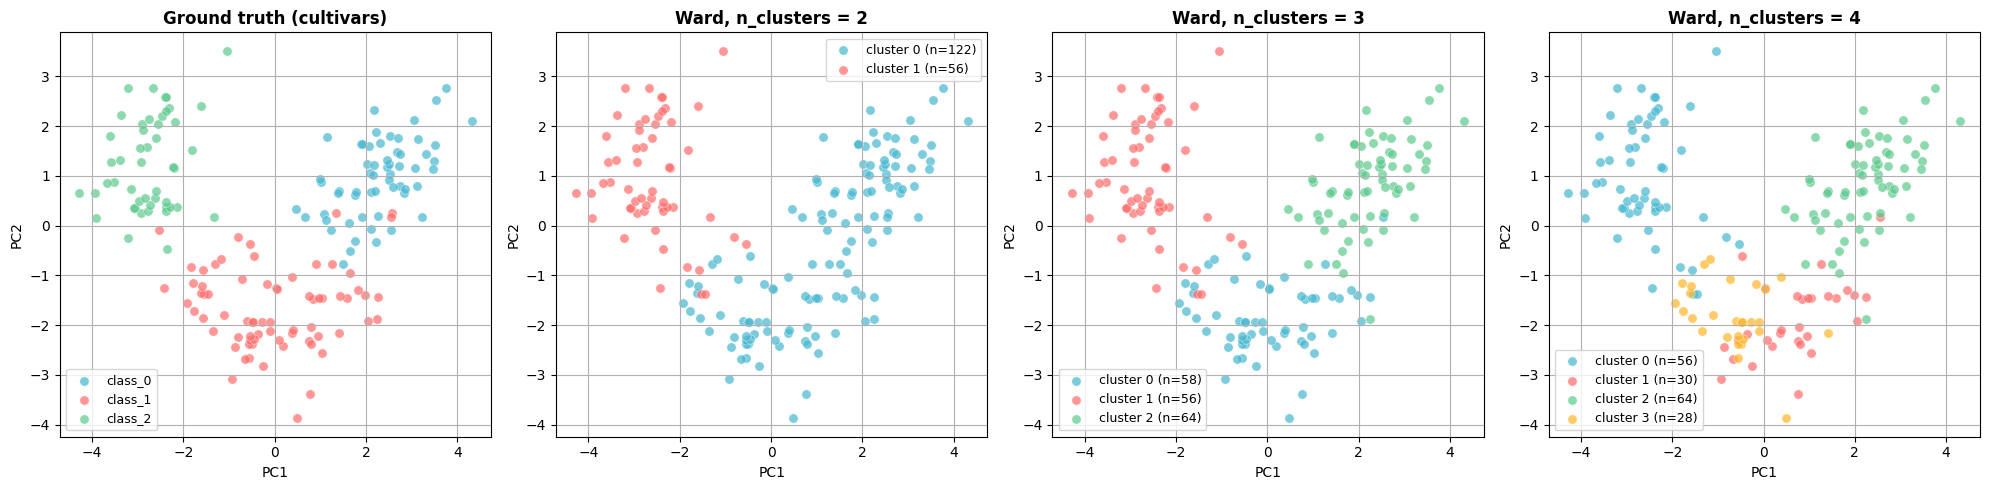

In [7]:
# Scatter plots for n_clusters = 2, 3, 4, with the true cultivars for reference
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
palette = ['#45B7D1', '#FF6B6B', '#5BC98C', '#FFB627', '#9B59B6']

ax = axes[0]
for c, name in enumerate(wine.target_names):
    m = y_true == c
    ax.scatter(X_2d[m, 0], X_2d[m, 1], s=45, alpha=0.7, color=palette[c],
               label=name, edgecolors='white', linewidths=0.4)
ax.set_title('Ground truth (cultivars)', fontweight='bold')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.legend(fontsize=9)

for ax, n in zip(axes[1:], [2, 3, 4]):
    lab = AgglomerativeClustering(n_clusters=n, linkage='ward').fit_predict(X)
    for c in range(n):
        m = lab == c
        ax.scatter(X_2d[m, 0], X_2d[m, 1], s=45, alpha=0.7, color=palette[c],
                   label=f'cluster {c} (n={m.sum()})', edgecolors='white', linewidths=0.4)
    ax.set_title(f'Ward, n_clusters = {n}', fontweight='bold')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

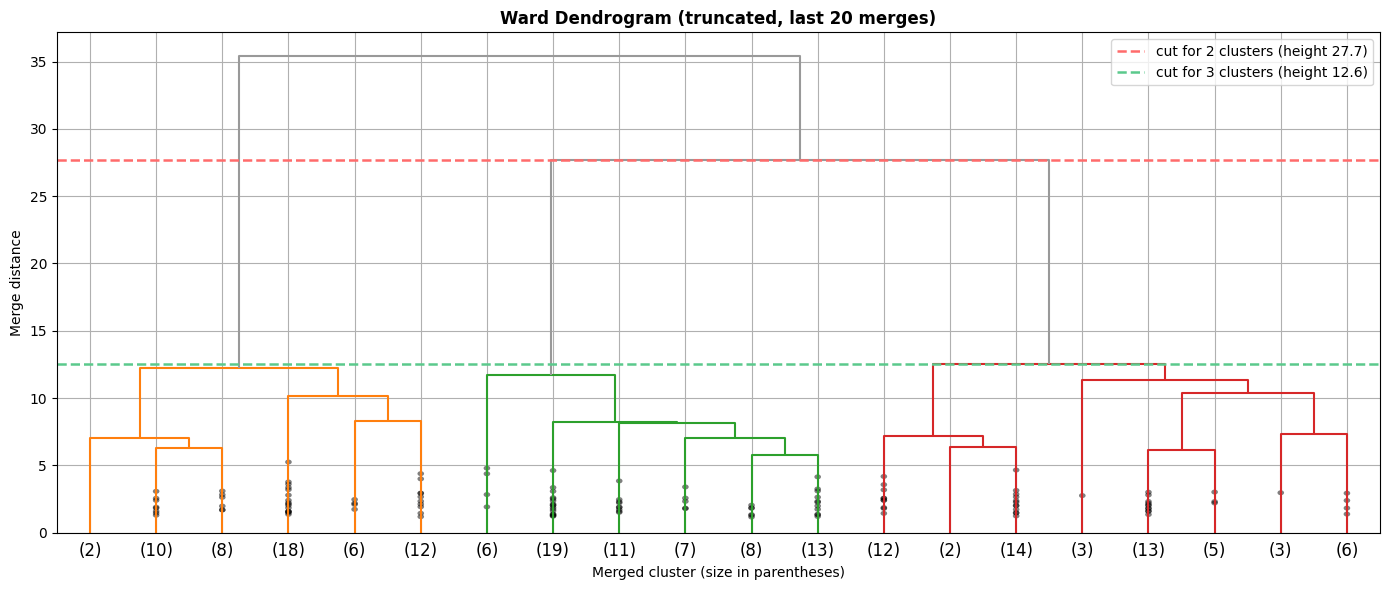

The final merge joins the last two clusters at height 35.4.
The 3-cluster cut sits at height 12.6 and the 2-cluster cut at 27.7.
The final merges are far apart in height (the last two jump sharply), while the earlier
merges are packed closely together. A large jump is a natural place to cut, and that
points to a small number of groups rather than many.


In [8]:
# Dendrogram. Truncated to the last 20 merges so the leaves stay readable.
Z = linkage(X, method='ward')

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=20, show_contracted=True, ax=ax,
           color_threshold=Z[-2, 2], above_threshold_color='#999999')
ax.axhline(Z[-2, 2], color='#FF6B6B', linestyle='--', linewidth=1.8,
           label=f'cut for 2 clusters (height {Z[-2, 2]:.1f})')
ax.axhline(Z[-3, 2], color='#5BC98C', linestyle='--', linewidth=1.8,
           label=f'cut for 3 clusters (height {Z[-3, 2]:.1f})')
ax.set_title('Ward Dendrogram (truncated, last 20 merges)', fontweight='bold')
ax.set_xlabel('Merged cluster (size in parentheses)')
ax.set_ylabel('Merge distance')
ax.legend()
plt.tight_layout()
plt.show()

print(f"The final merge joins the last two clusters at height {Z[-1,2]:.1f}.")
print(f"The 3-cluster cut sits at height {Z[-3,2]:.1f} and the 2-cluster cut at {Z[-2,2]:.1f}.")
print("The final merges are far apart in height (the last two jump sharply), while the earlier")
print("merges are packed closely together. A large jump is a natural place to cut, and that")
print("points to a small number of groups rather than many.")

---
## Step 3: DBSCAN Clustering

DBSCAN defines a cluster as a region where points are densely packed. Two parameters control this. `eps` is the neighborhood radius, and `min_samples` is how many neighbors a point needs within that radius to count as a core point. Points that cannot reach any core point are labelled noise (-1), and DBSCAN does not force them into a cluster.

### Choosing eps

The standard heuristic is a k-distance plot: for each point, measure the distance to its k-th nearest neighbour, sort those distances, and look for a knee. Points to the right of the knee sit in sparse regions.

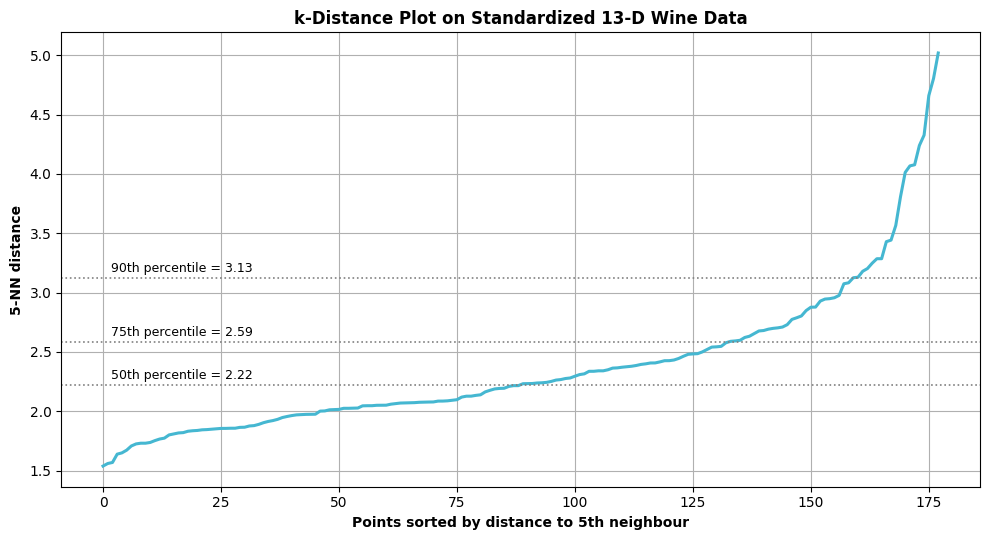

The curve climbs gradually with no sharp knee. In 13 dimensions distances tend to bunch
together, so the usual elbow is hard to see, and the plot suggests an eps somewhere
between about 2 and 3.


In [9]:
k = 5  # matches min_samples below
nn = NearestNeighbors(n_neighbors=k).fit(X)
dist, _ = nn.kneighbors(X)
kdist = np.sort(dist[:, -1])

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(kdist, color='#45B7D1', linewidth=2.2)
for p in [50, 75, 90]:
    v = np.percentile(kdist, p)
    ax.axhline(v, color='gray', linestyle=':', linewidth=1.2)
    ax.text(len(kdist)*0.01, v + 0.05, f'{p}th percentile = {v:.2f}', fontsize=9)
ax.set_xlabel('Points sorted by distance to 5th neighbour', fontweight='bold')
ax.set_ylabel('5-NN distance', fontweight='bold')
ax.set_title('k-Distance Plot on Standardized 13-D Wine Data', fontweight='bold')
plt.tight_layout()
plt.show()

print("The curve climbs gradually with no sharp knee. In 13 dimensions distances tend to bunch")
print("together, so the usual elbow is hard to see, and the plot suggests an eps somewhere")
print("between about 2 and 3.")

In [10]:
sweep = []
for eps in [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]:
    for ms in [3, 5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        mask = lab != -1
        n_clusters = len(set(lab[mask]))
        sil = silhouette_score(X[mask], lab[mask]) if n_clusters >= 2 else np.nan
        sweep.append({
            'eps': eps, 'min_samples': ms, 'clusters': n_clusters,
            'noise points': int((~mask).sum()),
            'silhouette (non-noise)': sil,
            'homogeneity': homogeneity_score(y_true, lab),
            'completeness': completeness_score(y_true, lab)
        })

sweep_df = pd.DataFrame(sweep)
print("DBSCAN on standardized 13-D features:")
print(sweep_df.round(4).to_string(index=False))

print(f"\nAcross the whole grid, the best homogeneity is {sweep_df['homogeneity'].max():.2f}, and most settings either")
print("collapse everything into one cluster or label a large share of wines as noise.")

DBSCAN on standardized 13-D features:
 eps  min_samples  clusters  noise points  silhouette (non-noise)  homogeneity  completeness
 1.5            3         8           147                  0.3311       0.1892        0.2510
 1.5            5         0           178                     NaN       0.0000        1.0000
 1.5           10         0           178                     NaN       0.0000        1.0000
 2.0            3         5            64                  0.2113       0.4423        0.3724
 2.0            5         5            85                  0.2405       0.3624        0.3247
 2.0           10         1           139                     NaN       0.2887        0.5963
 2.5            3         1            23                     NaN       0.0668        0.1885
 2.5            5         1            24                     NaN       0.0576        0.1581
 2.5           10         2            32                  0.3228       0.5045        0.5604
 3.0            3         2     

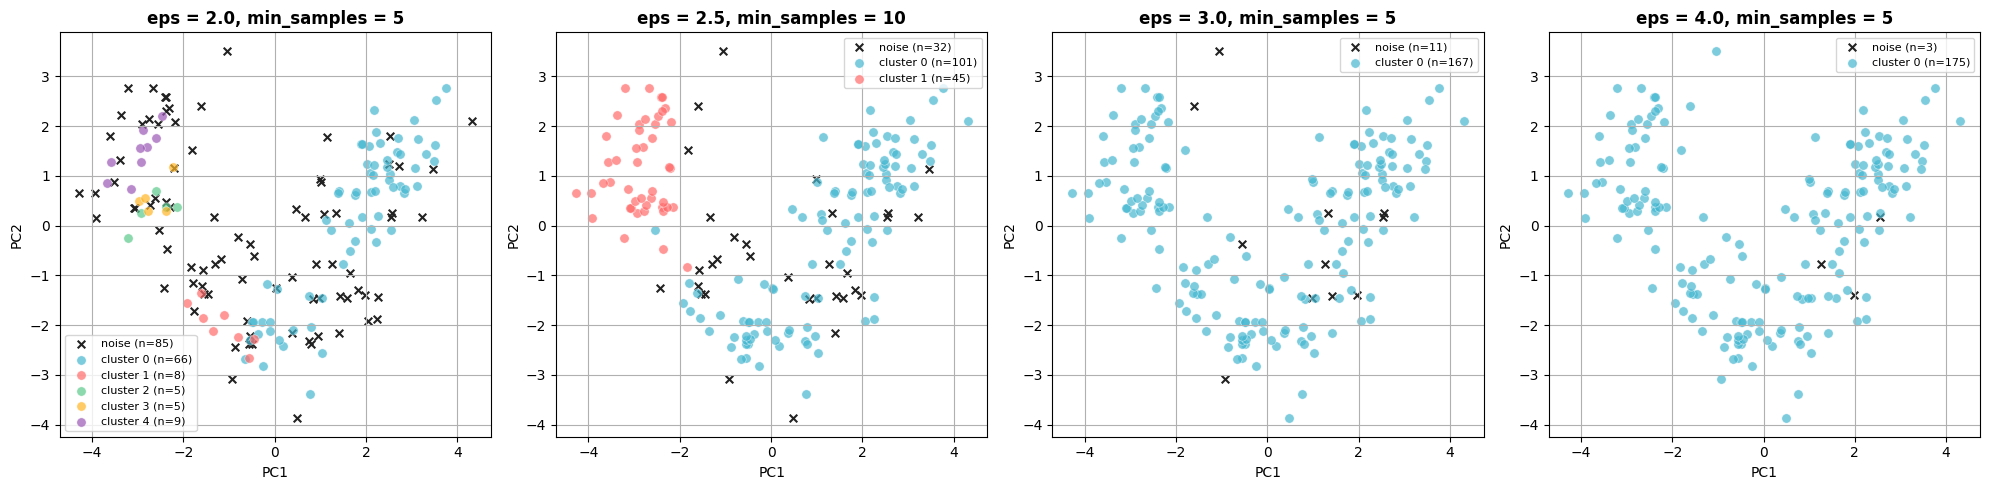

Raising eps merges clusters and shrinks the noise; raising min_samples does the opposite,
turning borderline points into noise. The two parameters trade off against each other.


In [11]:
# Show how the noise points change with the settings
settings = [(2.0, 5), (2.5, 10), (3.0, 5), (4.0, 5)]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
noise_color = '#222222'
palette = ['#45B7D1', '#FF6B6B', '#5BC98C', '#FFB627', '#9B59B6']

for ax, (eps, ms) in zip(axes, settings):
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
    for c in sorted(set(lab)):
        m = lab == c
        if c == -1:
            ax.scatter(X_2d[m, 0], X_2d[m, 1], s=30, marker='x', color=noise_color,
                       label=f'noise (n={m.sum()})')
        else:
            ax.scatter(X_2d[m, 0], X_2d[m, 1], s=45, alpha=0.7, color=palette[c % 5],
                       label=f'cluster {c} (n={m.sum()})', edgecolors='white', linewidths=0.4)
    ax.set_title(f'eps = {eps}, min_samples = {ms}', fontweight='bold')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Raising eps merges clusters and shrinks the noise; raising min_samples does the opposite,")
print("turning borderline points into noise. The two parameters trade off against each other.")

### Reducing dimensionality before DBSCAN

Thirteen dimensions is a hard setting for density-based methods. A second attempt projects the data onto its first few principal components before running DBSCAN. This discards some variance, so it is a deliberate trade-off rather than a free improvement. The results below compare the two approaches honestly.

In [12]:
rows = []
for nc in [2, 3, 5]:
    Z_pca = PCA(n_components=nc, random_state=42).fit_transform(X)
    kd = np.sort(NearestNeighbors(n_neighbors=5).fit(Z_pca).kneighbors(Z_pca)[0][:, -1])
    kept = PCA(n_components=nc).fit(X).explained_variance_ratio_.sum()
    rows.append({'components': nc, 'variance kept': round(kept, 3),
                 'median 5-NN dist': round(float(np.median(kd)), 3)})
print("Variance retained by each projection:")
print(pd.DataFrame(rows).to_string(index=False))

pca_sweep = []
Z3 = PCA(n_components=3, random_state=42).fit_transform(X)
for eps in [0.8, 0.9, 1.0, 1.1, 1.2, 1.4]:
    for ms in [5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z3)
        mask = lab != -1
        n_clusters = len(set(lab[mask]))
        sil = silhouette_score(Z3[mask], lab[mask]) if n_clusters >= 2 else np.nan
        pca_sweep.append({
            'eps': eps, 'min_samples': ms, 'clusters': n_clusters,
            'noise points': int((~mask).sum()),
            'silhouette (non-noise)': sil,
            'homogeneity': homogeneity_score(y_true, lab),
            'completeness': completeness_score(y_true, lab)
        })

pca_df = pd.DataFrame(pca_sweep)
print("\nDBSCAN on the first 3 principal components:")
print(pca_df.round(4).to_string(index=False))

Variance retained by each projection:
 components  variance kept  median 5-NN dist
          2          0.554             0.408
          3          0.665             0.839
          5          0.802             1.325

DBSCAN on the first 3 principal components:
 eps  min_samples  clusters  noise points  silhouette (non-noise)  homogeneity  completeness
 0.8            5         3            65                  0.6101       0.6214        0.5014
 0.8           10         4           119                  0.6957       0.3629        0.3718
 0.9            5         2            30                  0.4558       0.4464        0.5078
 0.9           10         5            81                  0.5273       0.5731        0.4188
 1.0            5         2            25                  0.4431       0.4532        0.5372
 1.0           10         3            48                  0.5711       0.7027        0.5538
 1.1            5         1            16                     NaN       0.0096        

Selected DBSCAN setting: eps = 1.0, min_samples = 10, on PCA(3)
  silhouette (non-noise)   0.5711
  homogeneity              0.7027
  completeness             0.5538
  noise points             48

Caveat: silhouette here excludes the noise points, which are the hardest cases to place.
That flatters the score, so the homogeneity and completeness values carry more weight.


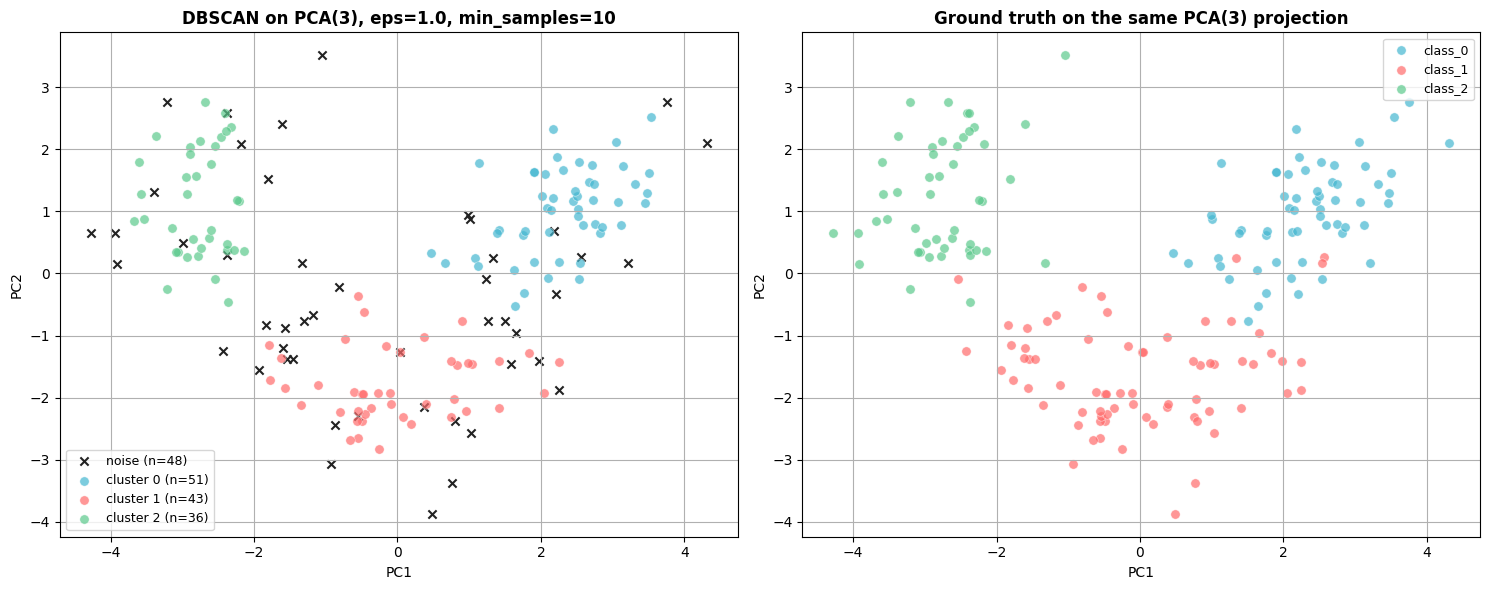

In [13]:
# Final DBSCAN setting for the comparison in Step 4
DB_EPS, DB_MS = 1.0, 10
db_lab_pca = DBSCAN(eps=DB_EPS, min_samples=DB_MS).fit_predict(Z3)
mask = db_lab_pca != -1

db_metrics = {
    'silhouette (non-noise)': silhouette_score(Z3[mask], db_lab_pca[mask]),
    'homogeneity': homogeneity_score(y_true, db_lab_pca),
    'completeness': completeness_score(y_true, db_lab_pca),
    'noise points': int((~mask).sum())
}

print(f"Selected DBSCAN setting: eps = {DB_EPS}, min_samples = {DB_MS}, on PCA(3)")
for key, val in db_metrics.items():
    print(f"  {key:24} {val:.4f}" if isinstance(val, float) else f"  {key:24} {val}")

print("\nCaveat: silhouette here excludes the noise points, which are the hardest cases to place.")
print("That flatters the score, so the homogeneity and completeness values carry more weight.")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for c in sorted(set(db_lab_pca)):
    m = db_lab_pca == c
    if c == -1:
        axes[0].scatter(Z3[m, 0], Z3[m, 1], s=35, marker='x', color='#222222',
                        label=f'noise (n={m.sum()})')
    else:
        axes[0].scatter(Z3[m, 0], Z3[m, 1], s=45, alpha=0.7, color=palette[c % 5],
                        label=f'cluster {c} (n={m.sum()})', edgecolors='white', linewidths=0.4)
axes[0].set_title(f'DBSCAN on PCA(3), eps={DB_EPS}, min_samples={DB_MS}', fontweight='bold')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].legend(fontsize=9)

for c in range(3):
    m = y_true == c
    axes[1].scatter(Z3[m, 0], Z3[m, 1], s=45, alpha=0.7, color=palette[c],
                    label=wine.target_names[c], edgecolors='white', linewidths=0.4)
axes[1].set_title('Ground truth on the same PCA(3) projection', fontweight='bold')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

---
## Step 4: Analysis and Insights

### Side-by-side comparison

The table below uses one setting from each method. For hierarchical clustering I use Ward with three clusters. For DBSCAN I use the PCA(3) setting selected above.

In [14]:
ward_lab = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X)

comparison = pd.DataFrame({
    'Method': ['Agglomerative (Ward, k=3)', 'DBSCAN (PCA-3, eps=1.0, min_samples=10)'],
    'Clusters': [3, len(set(db_lab_pca[mask]))],
    'Noise points': [0, db_metrics['noise points']],
    'Silhouette': [silhouette_score(X, ward_lab), db_metrics['silhouette (non-noise)']],
    'Homogeneity': [homogeneity_score(y_true, ward_lab), db_metrics['homogeneity']],
    'Completeness': [completeness_score(y_true, ward_lab), db_metrics['completeness']],
})
print(comparison.round(4).to_string(index=False))

print("\nSilhouette is not directly comparable across the two rows: the DBSCAN value ignores")
print("its noise points, while the Ward value includes every wine. Homogeneity and completeness")
print("are the fairer basis for comparison here, and on both of them Ward clearly leads.")

                                 Method  Clusters  Noise points  Silhouette  Homogeneity  Completeness
              Agglomerative (Ward, k=3)         3             0      0.2774       0.7904        0.7825
DBSCAN (PCA-3, eps=1.0, min_samples=10)         3            48      0.5711       0.7027        0.5538

Silhouette is not directly comparable across the two rows: the DBSCAN value ignores
its noise points, while the Ward value includes every wine. Homogeneity and completeness
are the fairer basis for comparison here, and on both of them Ward clearly leads.


### How parameters shaped the outcomes

**Hierarchical:** the number of clusters is the only real knob, and it has a clear effect. Asking for two clusters merges the cultivars that sit close together in chemistry, which lowers homogeneity to about 0.44. Three clusters recovers the true structure well, with homogeneity near 0.79. Going to four or five splits real groups: homogeneity holds or rises slightly, while completeness drops, because one cultivar now spreads across several clusters. The linkage choice matters as much as the cluster count. Single and average linkage chain through the data and fail completely on this dataset.

**DBSCAN:** the two parameters interact, so there is no single best setting. Larger eps joins neighbouring clusters and reduces noise. Larger min_samples does the reverse, classifying more borderline wines as noise. In the full 13-dimensional space the usable region is narrow, and the best homogeneity I found was about 0.50, at settings that split the wines into only two clusters. Projecting onto three principal components widened the usable region and raised the best homogeneity to about 0.70, but that still trails Ward, and the projection threw away about a third of the variance.

### Strengths and weaknesses

**Agglomerative clustering** works well here because the cultivars form compact groups that merge in a sensible order. The dendrogram is genuinely useful: it shows the hierarchy and lets you pick a cut after looking at the structure. Its weaknesses are cost, since the pairwise distance computation grows quickly with more samples, and the fact that merges are permanent. An early bad merge cannot be undone.

**DBSCAN** does not need the number of clusters in advance, handles irregular shapes, and reports noise explicitly. On this dataset those strengths did not translate into better clustering. High dimensionality flattens the density differences that DBSCAN depends on, so it needed a projection to work at all, and it still left many wines unassigned. Its best use is data with genuine density structure and real outliers, where the noise label carries information.

**Overall**, for a clean, roughly spherical, moderately high-dimensional dataset like this one, Ward agglomerative clustering is the stronger choice. DBSCAN earns its place when the data has irregular shapes or meaningful outliers, and the noise points themselves become part of the answer.

---
## Conclusion

Ward agglomerative clustering with three clusters recovered the cultivars best, with homogeneity 0.79 and completeness 0.78. DBSCAN was far more sensitive to its parameters. On the full standardized features it either collapsed the data or labelled a large share of wines as noise. Reducing to three principal components made it usable, reaching homogeneity 0.70 at the cost of discarding variance and leaving some wines unassigned. The main lesson is that algorithm choice should follow the geometry of the data: in this case, compact groups in moderate dimension favour hierarchical clustering, and the density-based approach needs more structure than this dataset provides.

---
**End of Lab Report**